# Network Intrusion Detection System using Machine Learning

## 1. Project Introduction

### What is Network Intrusion Detection?
A Network Intrusion Detection System (NIDS) watches network traffic and tries to spot malicious or suspicious activity, such as port scans, denial-of-service floods, or password-guessing attempts.

### What does this project do?
Given the characteristics of one network connection (duration, protocol, bytes sent, error rates, and so on), a supervised machine learning model predicts whether the connection is:

- Normal (label 0)
- Attack (label 1)

This is a binary classification problem. I train four classical models (Logistic Regression, Decision Tree, Random Forest, XGBoost), compare them, and evaluate the best one on a separate test file.

### Dataset: NSL-KDD
I chose NSL-KDD because it is small enough for Google Colab (about 126k training rows, 22k test rows), has 41 well-documented features, has clear normal/attack labels, and needs very little preprocessing. It is a cleaned version of the older KDD Cup 1999 dataset (duplicate records were removed). CICIDS2017 is several GB and UNSW-NB15 is larger and messier, which would distract from the ML concepts.

- Target column: `label` (the connection type, e.g. `normal`, `neptune`, `smurf`). We convert it into a binary `attack` column.
- Important features: `protocol_type`, `service`, `flag` (categorical); `src_bytes`, `dst_bytes`, `duration`, `count`, `srv_count`, `serror_rate`, `same_srv_rate`, `dst_host_srv_count` (numeric).
- Attack families in the data: DoS (e.g. neptune, smurf), Probe (e.g. satan, ipsweep), R2L (e.g. guess_passwd) and U2R (e.g. buffer_overflow). In this project all of them are grouped into one class called Attack.

Possible future extension: predict the attack family (multi-class) instead of only normal vs attack.

Note on the test set: the official test file (`KDDTest+`) contains attack types that never appear in training, so it is a harder and more realistic check than a random split. Expect a lower score there than on the random split. That gap is a good interview discussion point.

## 2. Import Libraries

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import joblib

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 3. Load Dataset

The NSL-KDD files are plain text with no header row, so we first load them without column names and look at the raw data. Then we attach the official 41 feature names, plus the label column and a `difficulty_level` column that the dataset authors added.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master"
TRAIN_URL = f"{BASE_URL}/KDDTrain%2B.txt"
TEST_URL  = f"{BASE_URL}/KDDTest%2B.txt"

raw = pd.read_csv(TRAIN_URL, header=None)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (125973, 43)


,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [3]:
# Official NSL-KDD column names (41 features + label + difficulty level)
COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_srv_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty_level",
]

# Safety check: the number of names must match the number of columns in the file
assert len(COLUMNS) == raw.shape[1], f"Expected {raw.shape[1]} columns, got {len(COLUMNS)}"

df = raw.copy()
df.columns = COLUMNS
df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 4. Understand Dataset

In [4]:
print("Rows, columns:", df.shape)
print()
df.info()

Rows, columns: (125973, 43)

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-

In [5]:
# Categorical vs numeric columns
categorical_cols = df.select_dtypes(include="object").columns.tolist()
print("Text (categorical) columns:", categorical_cols)
print()
print(df[categorical_cols].nunique())

Text (categorical) columns: ['protocol_type', 'service', 'flag', 'label']

protocol_type     3
service          70
flag             11
label            23
dtype: int64


In [6]:
df.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.0,0.0,0.0,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.0,44.0,276.0,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.0,0.0,516.0,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.0,0.0,0.0,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.0,0.0,0.0,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.0,0.0,0.0,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.0,0.0,0.0,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.0,0.0,0.0,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.0,0.0,1.0,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.0,0.0,0.0,7.479000e+03


In [7]:
# What do the labels look like?
print(df["label"].value_counts())

label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64


The `label` column has one `normal` value and many attack names. Most attack names are rare. We will group all of them into a single Attack class in the Target Creation step.

## 5. Data Cleaning

In [8]:
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Missing values: 0
Duplicate rows: 0


In [9]:
# difficulty_level is metadata added by the dataset authors (how hard a record was to
# classify for their benchmark models). It is not a property of the network traffic,
# so using it as a feature would be wrong. Drop it.
df = df.drop(columns=["difficulty_level"])

# Constant columns carry no information
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns:", constant_cols)
df = df.drop(columns=constant_cols)

print("Shape after cleaning:", df.shape)

Constant columns: ['num_outbound_cmds']
Shape after cleaning: (125973, 41)


NSL-KDD has no missing values and no duplicate rows (the authors removed duplicates from the original KDD'99 data), so cleaning is short. In an interview, mention that removing duplicates is one of the main reasons NSL-KDD exists.

## 6. Exploratory Data Analysis

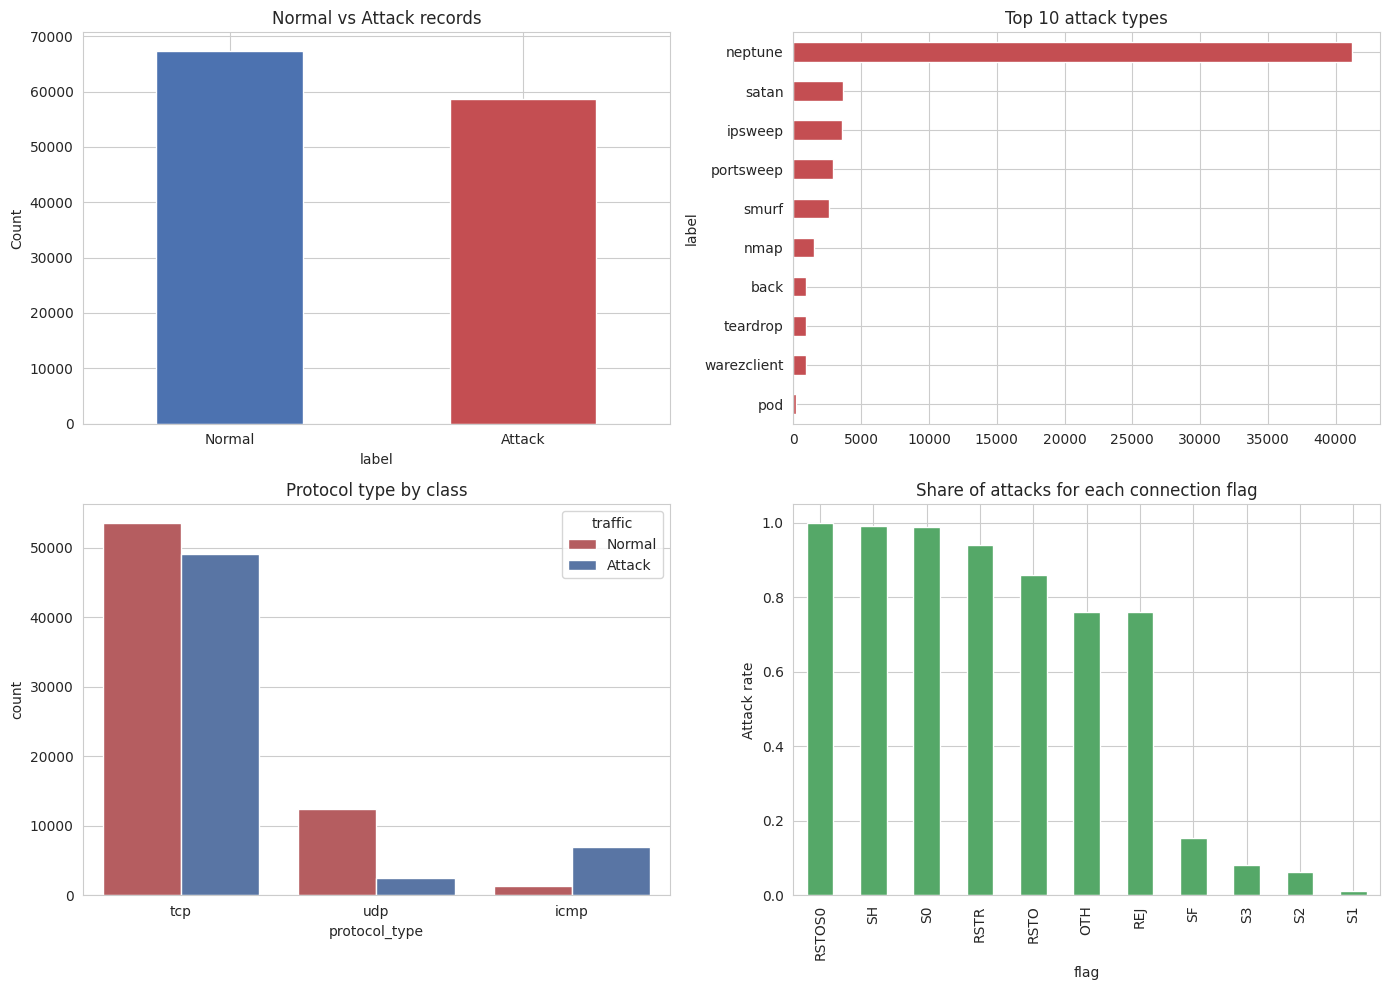

In [10]:
is_attack = df["label"] != "normal"

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Normal vs attack
is_attack.map({False: "Normal", True: "Attack"}).value_counts().plot(
    kind="bar", ax=axes[0, 0], color=["#4C72B0", "#C44E52"])
axes[0, 0].set_title("Normal vs Attack records")
axes[0, 0].set_ylabel("Count")
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Most common attack types
df.loc[is_attack, "label"].value_counts().head(10).plot(
    kind="barh", ax=axes[0, 1], color="#C44E52")
axes[0, 1].set_title("Top 10 attack types")
axes[0, 1].invert_yaxis()

# 3. Protocol vs class
sns.countplot(data=df.assign(traffic=is_attack.map({False: "Normal", True: "Attack"})),
              x="protocol_type", hue="traffic", ax=axes[1, 0],
              palette=["#C44E52", "#4C72B0"])
axes[1, 0].set_title("Protocol type by class")

# 4. Attack rate per connection flag
attack_rate = is_attack.groupby(df["flag"]).mean().sort_values(ascending=False)
attack_rate.plot(kind="bar", ax=axes[1, 1], color="#55A868")
axes[1, 1].set_title("Share of attacks for each connection flag")
axes[1, 1].set_ylabel("Attack rate")

plt.tight_layout()
plt.show()

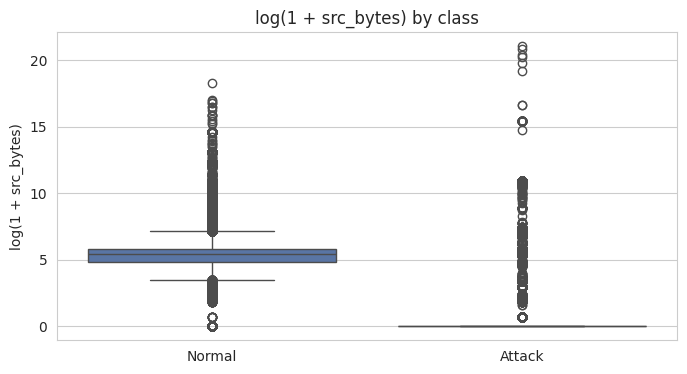

In [11]:
# src_bytes is heavily skewed, so use a log scale to compare classes
plt.figure(figsize=(8, 4))
sns.boxplot(x=is_attack.map({False: "Normal", True: "Attack"}),
            y=np.log1p(df["src_bytes"]), palette=["#4C72B0", "#C44E52"])
plt.title("log(1 + src_bytes) by class")
plt.ylabel("log(1 + src_bytes)")
plt.xlabel("")
plt.show()

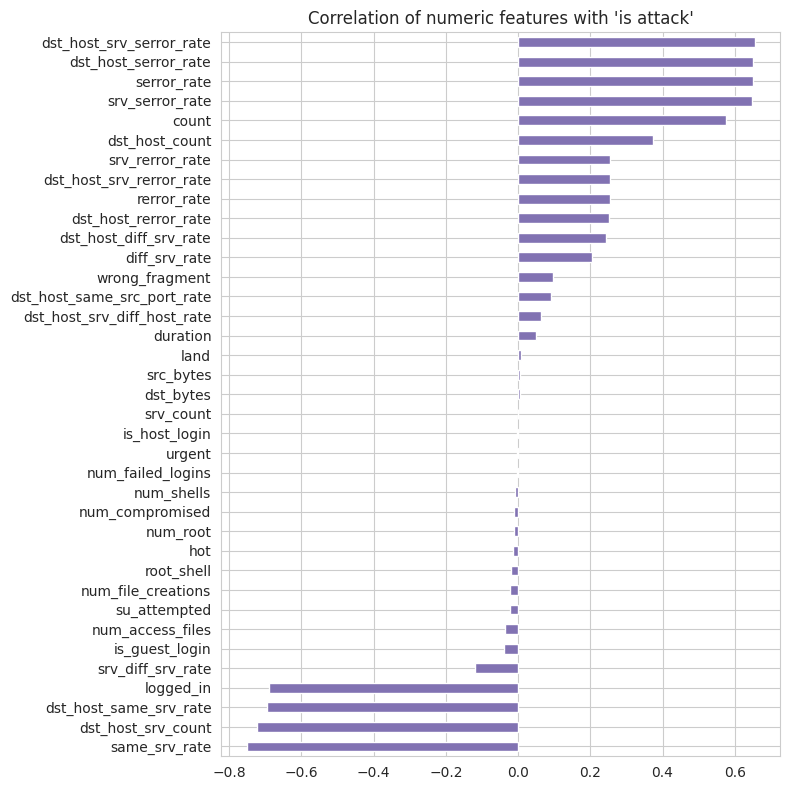

In [12]:
# Which numeric features move most with 'is attack'?
corr = df.select_dtypes(include=np.number).corrwith(is_attack.astype(int)).sort_values()
plt.figure(figsize=(8, 8))
corr.plot(kind="barh", color="#8172B2")
plt.title("Correlation of numeric features with 'is attack'")
plt.tight_layout()
plt.show()

Observations to note:

- The classes are fairly balanced (roughly 53% normal, 47% attack), so accuracy is a meaningful metric here and we do not need resampling.
- Attack counts are dominated by a few types (neptune, satan, ipsweep, portsweep, smurf). Many attack types have only a handful of rows.
- Error-rate features (`serror_rate`, `srv_serror_rate`) and `same_srv_rate` are strongly related to the class. Many attacks (like SYN floods) create lots of failed connections to the same service.

## 7. Feature Selection

In [13]:
# We keep all remaining features. Only useless columns were removed (difficulty_level and
# constant columns). We now split them by type because they need different preprocessing.
feature_cols = [c for c in df.columns if c != "label"]

categorical_features = ["protocol_type", "service", "flag"]
numeric_features = [c for c in feature_cols if c not in categorical_features]

print("Total features:", len(feature_cols))
print("Categorical:", categorical_features)
print("Numeric:", len(numeric_features))

Total features: 40
Categorical: ['protocol_type', 'service', 'flag']
Numeric: 37


## 8. Target Creation

We convert the `label` column into a binary target called `attack`:

- 0 = normal
- 1 = attack (every attack type)

The original `label` column is kept only for analysis, not as a model input.

In [14]:
df["attack"] = (df["label"] != "normal").astype(int)

X = df[feature_cols]
y = df["attack"]

print(y.value_counts())
print()
print(y.value_counts(normalize=True).round(3))

attack
0    67343
1    58630
Name: count, dtype: int64

attack
0    0.535
1    0.465
Name: proportion, dtype: float64


## 9. Train/Test Split

An 80/20 split with `stratify=y` keeps the same normal/attack ratio in both parts. I call the 20% part the validation set to avoid mixing it up with `test.csv`, which is used at the very end.

In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Validation:", X_val.shape)

Train: (100778, 40)  Validation: (25195, 40)


## 10. Feature Scaling / Encoding

- Categorical columns (`protocol_type`, `service`, `flag`) are one-hot encoded. `handle_unknown="ignore"` matters because `test.csv` can contain a service that never appeared in training.
- Numeric columns are standardized with `StandardScaler`. This is required for Logistic Regression. Tree-based models do not need it but it does not hurt them, so all four models share one preprocessing step.
- The preprocessor is fitted on the training data only, then reused on validation and test data. This avoids data leakage. The same fitted object is saved later for Streamlit.

In [16]:
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ("num", StandardScaler(), numeric_features),
])

X_train_p = preprocessor.fit_transform(X_train)   # learn from train only
X_val_p   = preprocessor.transform(X_val)         # only apply to validation

feature_names = preprocessor.get_feature_names_out()
print("Features after encoding:", X_train_p.shape[1])

Features after encoding: 120


In [17]:
# Helper: train a model, score it on the validation set, and store the results
models = {}
results = []

def train_and_evaluate(name, model):
    model.fit(X_train_p, y_train)
    pred = model.predict(X_val_p)
    proba = model.predict_proba(X_val_p)[:, 1]

    scores = {
        "Model": name,
        "Accuracy":  accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall":    recall_score(y_val, pred),
        "F1-score":  f1_score(y_val, pred),
        "ROC-AUC":   roc_auc_score(y_val, proba),
    }
    models[name] = model
    results.append(scores)

    print(f"--- {name} ---")
    print(classification_report(y_val, pred, target_names=["Normal", "Attack"], digits=4))
    return model

## 11. Model 1 — Logistic Regression

A linear model that outputs the probability of an attack. It is a good simple baseline and easy to explain.

In [18]:
train_and_evaluate("Logistic Regression",
                   LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

--- Logistic Regression ---
              precision    recall  f1-score   support

      Normal     0.9682    0.9796    0.9738     13469
      Attack     0.9762    0.9630    0.9696     11726

    accuracy                         0.9719     25195
   macro avg     0.9722    0.9713    0.9717     25195
weighted avg     0.9719    0.9719    0.9718     25195



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

## 12. Model 2 — Decision Tree

Learns a sequence of if/else rules on the features. It is easy to interpret but can overfit if it grows too deep.

In [19]:
train_and_evaluate("Decision Tree",
                   DecisionTreeClassifier(max_depth=15, random_state=RANDOM_STATE))

--- Decision Tree ---
              precision    recall  f1-score   support

      Normal     0.9984    0.9981    0.9983     13469
      Attack     0.9978    0.9982    0.9980     11726

    accuracy                         0.9981     25195
   macro avg     0.9981    0.9981    0.9981     25195
weighted avg     0.9981    0.9981    0.9981     25195



,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current n

## 13. Model 3 — Random Forest

Many decision trees trained on random samples of the data, with predictions combined by voting. It is more stable and less prone to overfitting than a single tree.

In [20]:
train_and_evaluate("Random Forest",
                   RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE))

--- Random Forest ---
              precision    recall  f1-score   support

      Normal     0.9987    0.9996    0.9991     13469
      Attack     0.9995    0.9985    0.9990     11726

    accuracy                         0.9990     25195
   macro avg     0.9991    0.9990    0.9990     25195
weighted avg     0.9990    0.9990    0.9990     25195



,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## 14. Model 4 — XGBoost

Builds trees one after another, where each new tree tries to correct the mistakes of the previous ones (gradient boosting). It is often the strongest model on tabular data.

In [21]:
train_and_evaluate("XGBoost",
                   XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                 eval_metric="logloss", random_state=RANDOM_STATE))

--- XGBoost ---
              precision    recall  f1-score   support

      Normal     0.9993    0.9993    0.9993     13469
      Attack     0.9992    0.9992    0.9992     11726

    accuracy                         0.9993     25195
   macro avg     0.9993    0.9993    0.9993     25195
weighted avg     0.9993    0.9993    0.9993     25195



,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

## 15. Model Comparison

Attack is the positive class. Precision answers "when the model says attack, how often is it right?". Recall answers "of all real attacks, how many did the model catch?". For intrusion detection, recall matters a lot because a missed attack is costly, but low precision creates false alarms, so F1 balances both.

In [22]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.9719,0.9762,0.9630,0.9696,0.9963
Decision Tree,0.9981,0.9978,0.9982,0.9980,0.9988
Random Forest,0.9990,0.9995,0.9985,0.9990,1.0000
XGBoost,0.9993,0.9992,0.9992,0.9992,1.0000


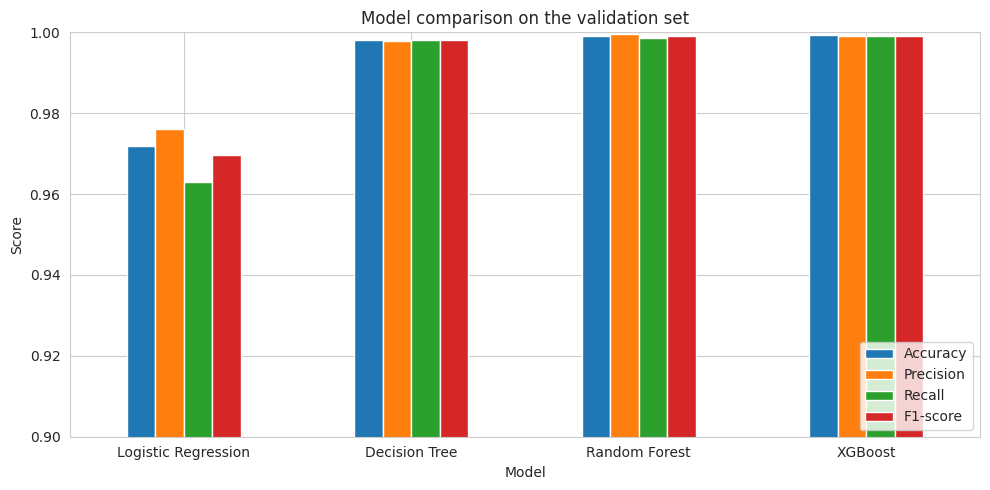

In [23]:
results_df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0.9, 1.0))
plt.title("Model comparison on the validation set")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 16. Confusion Matrix

Rows are the true class and columns are the predicted class. The top-right cell is false alarms (normal predicted as attack). The bottom-left cell is missed attacks (attack predicted as normal).

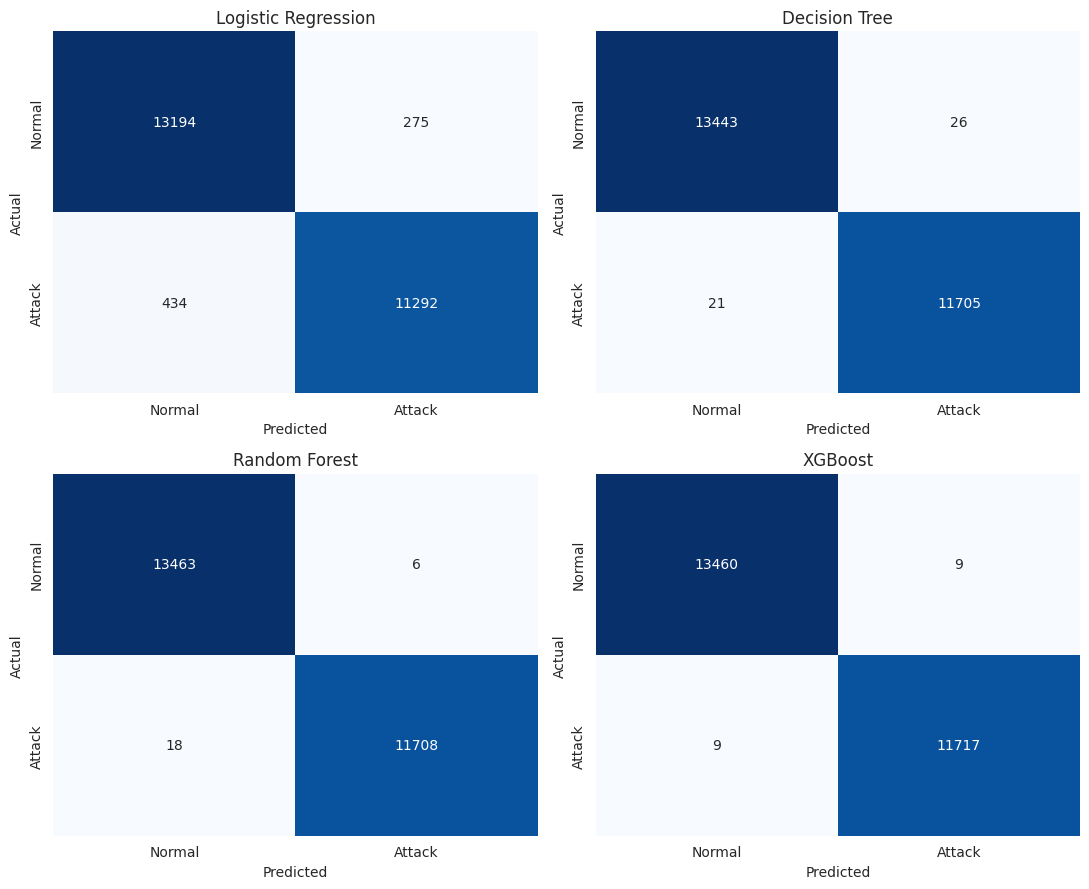

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    cm = confusion_matrix(y_val, model.predict(X_val_p))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 17. Final Model Selection

The final model is chosen using the validation set only (highest F1-score, recall as tie-breaker). `test.csv` is not used for choosing, so its result stays an honest estimate.

In [25]:
best_name = results_df.sort_values(["F1-score", "Recall"], ascending=False).index[0]
final_model = models[best_name]

print("Selected final model:", best_name)
results_df.loc[[best_name]]

Selected final model: XGBoost


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
XGBoost,0.9993,0.9992,0.9992,0.9992,1.0


If two models are almost tied (for example Random Forest and XGBoost differing in the third decimal), the difference is within noise. In that case either choice is defensible. Be ready to explain the trade-off: XGBoost is often slightly more accurate, Random Forest is simpler to tune.

## 18. Feature Importance

Shows which features the final model relied on most. One-hot encoded columns appear individually (for example `cat__service_http`).

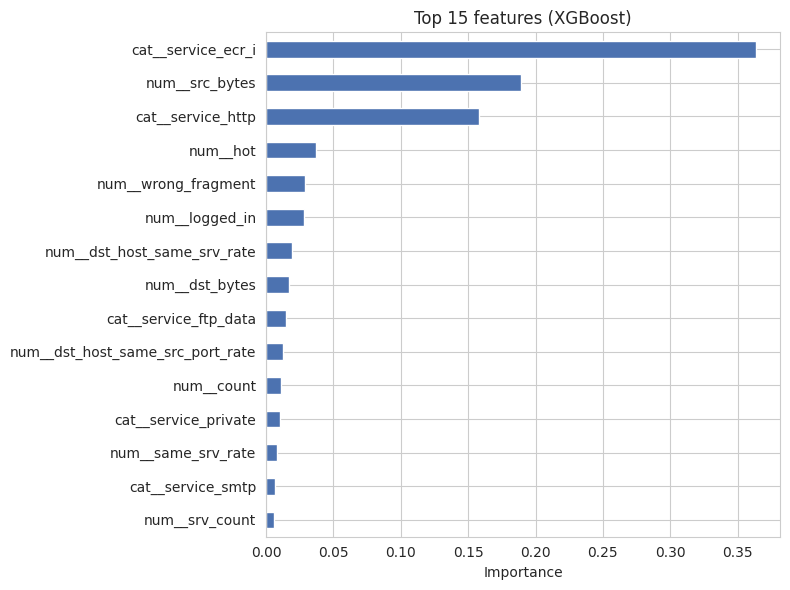

cat__service_ecr_i                  0.363333
num__src_bytes                      0.189252
cat__service_http                   0.157917
num__hot                            0.037069
num__wrong_fragment                 0.028805
num__logged_in                      0.027934
num__dst_host_same_srv_rate         0.018888
num__dst_bytes                      0.017102
cat__service_ftp_data               0.015001
num__dst_host_same_src_port_rate    0.012434
num__count                          0.010700
cat__service_private                0.010442
num__same_srv_rate                  0.008214
cat__service_smtp                   0.006683
num__srv_count                      0.005942
dtype: float32

In [26]:
if hasattr(final_model, "feature_importances_"):
    importances = final_model.feature_importances_
    label = "Importance"
else:  # Logistic Regression: use absolute coefficient size
    importances = np.abs(final_model.coef_[0])
    label = "|Coefficient|"

importance_df = (pd.Series(importances, index=feature_names)
                   .sort_values(ascending=False).head(15))

plt.figure(figsize=(8, 6))
importance_df.iloc[::-1].plot(kind="barh", color="#4C72B0")
plt.title(f"Top 15 features ({best_name})")
plt.xlabel(label)
plt.tight_layout()
plt.show()

importance_df

In this run the most important features were the service `ecr_i` (ICMP echo replies, the signature of smurf floods), `src_bytes`, the service `http`, and `hot`, `wrong_fragment`, `logged_in`. Importance values can change slightly between runs. Note that one-hot columns split a categorical feature into several pieces, so the importance of `service` is spread across many `cat__service_*` rows.

## 19. Test on test.csv

`test.csv` is the official NSL-KDD test file (`KDDTest+`) with a header row. It contains attack types that are not in the training data, so it checks how well the model generalizes to new attacks.

The notebook uses `test.csv` if it is in the current folder (upload it in Colab from the left sidebar). If not, it downloads the original file and creates `test.csv` for you.

In [27]:
if os.path.exists("test.csv"):
    test_df = pd.read_csv("test.csv")
    print("Loaded local test.csv")
else:
    test_df = pd.read_csv(TEST_URL, header=None, names=COLUMNS)
    test_df.to_csv("test.csv", index=False)
    print("Downloaded KDDTest+ and saved it as test.csv")

print("Shape:", test_df.shape)
test_df.head()

Downloaded KDDTest+ and saved it as test.csv
Shape: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level
0,0,tcp,private,REJ,0,0,0,0,0,0,...,0.04,0.06,0.00,0.00,0.0,0.0,1.00,1.00,neptune,21
1,0,tcp,private,REJ,0,0,0,0,0,0,...,0.00,0.06,0.00,0.00,0.0,0.0,1.00,1.00,neptune,21
2,2,tcp,ftp_data,SF,12983,0,0,0,0,0,...,0.61,0.04,0.61,0.02,0.0,0.0,0.00,0.00,normal,21
3,0,icmp,eco_i,SF,20,0,0,0,0,0,...,1.00,0.00,1.00,0.28,0.0,0.0,0.00,0.00,saint,15
4,1,tcp,telnet,RSTO,0,15,0,0,0,0,...,0.31,0.17,0.03,0.02,0.0,0.0,0.83,0.71,mscan,11


Final model on test.csv: XGBoost
Accuracy : 0.7941
Precision: 0.9685
Recall   : 0.6598
F1-score : 0.7849


ROC-AUC  : 0.9670

              precision    recall  f1-score   support

      Normal     0.6837    0.9717    0.8026      9711
      Attack     0.9685    0.6598    0.7849     12833

    accuracy                         0.7941     22544
   macro avg     0.8261    0.8157    0.7938     22544
weighted avg     0.8458    0.7941    0.7925     22544



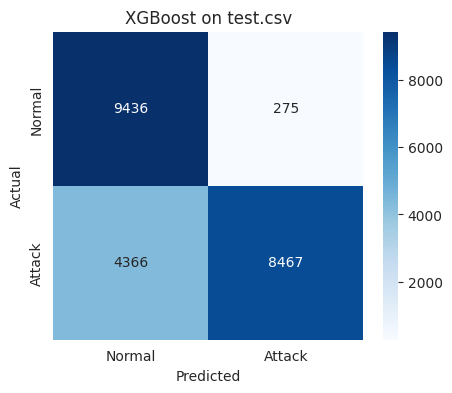

In [28]:
# Same steps as training: use the same feature columns and the already-fitted preprocessor
X_test = test_df[feature_cols]
y_test = (test_df["label"] != "normal").astype(int)
X_test_p = preprocessor.transform(X_test)

test_pred = final_model.predict(X_test_p)
test_proba = final_model.predict_proba(X_test_p)[:, 1]

print(f"Final model on test.csv: {best_name}")
print(f"Accuracy : {accuracy_score(y_test, test_pred):.4f}")
print(f"Precision: {precision_score(y_test, test_pred):.4f}")
print(f"Recall   : {recall_score(y_test, test_pred):.4f}")
print(f"F1-score : {f1_score(y_test, test_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, test_proba):.4f}")
print()
print(classification_report(y_test, test_pred, target_names=["Normal", "Attack"], digits=4))

cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.title(f"{best_name} on test.csv")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [29]:
# All four models on test.csv, for reference only (the choice was already made on validation)
rows = []
for name, model in models.items():
    p = model.predict(X_test_p)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1-score": f1_score(y_test, p)})
pd.DataFrame(rows).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.7539,0.9170,0.6242,0.7428
Decision Tree,0.7976,0.9204,0.7054,0.7987
Random Forest,0.7815,0.9693,0.6364,0.7683
XGBoost,0.7941,0.9685,0.6598,0.7849


In [30]:
# Which attack types does the final model miss? (detection rate per attack type)
by_type = (test_df.assign(pred=test_pred)
           .query("label != 'normal'")
           .groupby("label")["pred"].agg(["count", "mean"])
           .rename(columns={"count": "records", "mean": "detected_share"})
           .sort_values("records", ascending=False))
by_type["detected_share"] = by_type["detected_share"].round(3)

seen_in_training = set(df["label"].unique())
by_type["seen_in_training"] = by_type.index.isin(seen_in_training)
by_type.head(15)

,records,detected_share,seen_in_training
label,,,
neptune,4657,1.000,True
guess_passwd,1231,0.000,True
mscan,996,0.308,False
warezmaster,944,0.227,True
apache2,737,0.815,False
satan,735,1.000,True
processtable,685,0.232,False
smurf,665,1.000,True
back,359,1.000,True


Interpretation: high-volume attacks that are well represented in training (neptune, smurf, satan, back, portsweep, ipsweep) are detected almost perfectly. The misses come from two sources: attack types that never appear in training (for example snmpguess, mailbomb, snmpgetattack, and partly mscan and processtable), and rare attack types with very few training rows (for example guess_passwd with only 53 rows, warezmaster with 20). This is why recall drops on test.csv while precision stays high: when the model says attack it is usually right, but it misses attacks it has not learned. Detecting brand-new attacks would need anomaly detection, and rare classes could be helped by class weights or resampling. Both are outside the scope of this project.

## 20. Save Final Model

Three objects are saved so a Streamlit app can load them later: the fitted preprocessor, the trained model, and the list of input columns.

In [31]:
joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(final_model, "nids_model.pkl")
joblib.dump({"feature_cols": feature_cols,
             "categorical_features": categorical_features,
             "numeric_features": numeric_features,
             "model_name": best_name}, "metadata.pkl")

print("Saved: preprocessor.pkl, nids_model.pkl, metadata.pkl")

Saved: preprocessor.pkl, nids_model.pkl, metadata.pkl


In [32]:
# Quick check that the saved files work: this is what a Streamlit app would do
loaded_pre = joblib.load("preprocessor.pkl")
loaded_model = joblib.load("nids_model.pkl")
meta = joblib.load("metadata.pkl")

sample = test_df[meta["feature_cols"]].sample(5, random_state=1)
pred = loaded_model.predict(loaded_pre.transform(sample))
prob = loaded_model.predict_proba(loaded_pre.transform(sample))[:, 1]

out = pd.DataFrame({"actual_label": test_df.loc[sample.index, "label"],
                    "prediction": np.where(pred == 1, "ATTACK", "NORMAL"),
                    "attack_probability": prob.round(3)})
out

,actual_label,prediction,attack_probability
13003,guess_passwd,NORMAL,0.009
8908,neptune,ATTACK,1.000
11599,normal,NORMAL,0.000
20226,normal,NORMAL,0.000
11643,guess_passwd,NORMAL,0.000


In [33]:
# In Google Colab, uncomment to download the saved files:
# from google.colab import files
# for f in ["preprocessor.pkl", "nids_model.pkl", "metadata.pkl"]:
#     files.download(f)

## 21. Final Project Summary

In [34]:
print("PROJECT SUMMARY")
print("=" * 50)
print("Dataset            : NSL-KDD (KDDTrain+ / KDDTest+)")
print(f"Training records   : {len(df):,}")
print(f"Features used      : {len(feature_cols)} ({len(categorical_features)} categorical, {len(numeric_features)} numeric)")
print("Task               : Binary classification (Normal vs Attack)")
print(f"Best model (valid.): {best_name}")
print(f"  Validation F1    : {results_df.loc[best_name, 'F1-score']:.4f}")
print(f"  test.csv F1      : {f1_score(y_test, test_pred):.4f}")
print(f"  test.csv Recall  : {recall_score(y_test, test_pred):.4f}")

PROJECT SUMMARY
Dataset            : NSL-KDD (KDDTrain+ / KDDTest+)
Training records   : 125,973
Features used      : 40 (3 categorical, 37 numeric)
Task               : Binary classification (Normal vs Attack)
Best model (valid.): XGBoost
  Validation F1    : 0.9992
  test.csv F1      : 0.7849
  test.csv Recall  : 0.6598


### What I did
1. Loaded NSL-KDD, attached column names, and cleaned it (dropped `difficulty_level` and constant columns).
2. Explored class balance, attack types, protocols, and feature relationships.
3. Converted the label to Normal (0) vs Attack (1).
4. Split the data with stratification, one-hot encoded categorical features, and scaled numeric features (fitted on training data only).
5. Trained Logistic Regression, Decision Tree, Random Forest, and XGBoost and compared them with accuracy, precision, recall, F1, and confusion matrices.
6. Selected the final model on validation data and evaluated it on `test.csv`.
7. Saved the preprocessor and model with joblib for a future Streamlit app.

### Limitations
- The score on `test.csv` is lower than on the random validation split, because the test file has new attack types and a different mix of traffic.
- NSL-KDD is based on 1999-era traffic, so it is a learning benchmark, not a modern production dataset.
- Supervised models only detect attack patterns similar to what they saw during training.

### Future work
- Multi-class classification (DoS, Probe, R2L, U2R).
- Hyperparameter tuning with cross-validation.
- Handling the R2L/U2R attacks that are rare, using class weights.
- A Streamlit app for predictions.